In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [3]:
from pathlib import Path
file_path= Path("../data/raw/processed.cleveland.data")
df = pd.read_csv(
    file_path,
    header=None,
    na_values="?"
)


In [4]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [5]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

df.columns = columns

df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
df["target"] = (df["num"]>0).astype(int)
df[["num","target"]].sample(5)

,num,target
193,2,1
78,0,0
195,3,1
235,3,1
30,0,0


In [7]:
df.shape

(303, 15)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
 14  target    303 non-null    int64  
dtypes: float64(13), int64(2)
memory usage: 35.6 KB


In [9]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
target      0
dtype: int64

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [11]:
df.duplicated().sum()

np.int64(0)

## UNIVARIATE ANALYSIS

### AGE 

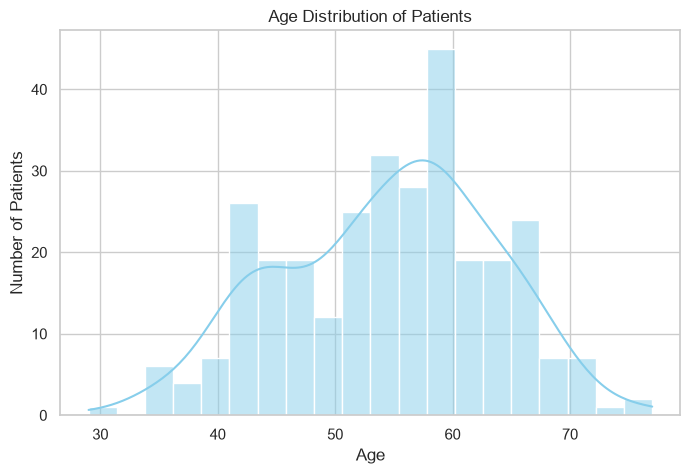

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=20,
    kde=True,
    color="skyblue"
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")
plt.show()

### Gender

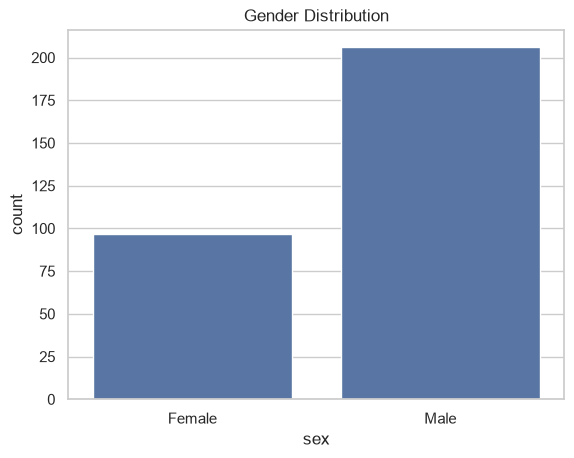

In [13]:
sns.countplot(data=df, x="sex")

plt.title("Gender Distribution")
plt.xticks([0, 1], ["Female", "Male"])
plt.show()

### Heart Disease

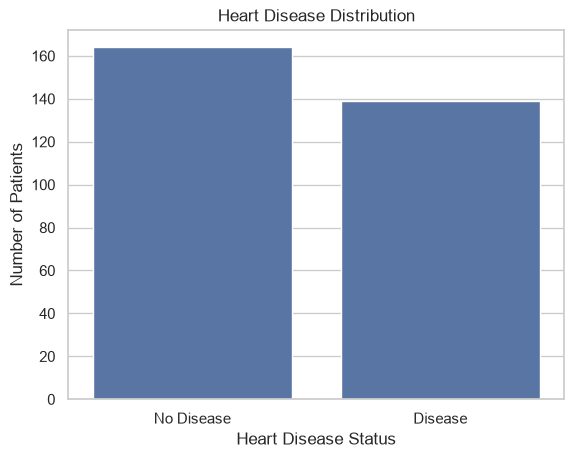

In [14]:
sns.countplot(data=df, x="target")

plt.title("Heart Disease Distribution")
plt.xticks([0, 1], ["No Disease", "Disease"])
plt.xlabel("Heart Disease Status")
plt.ylabel("Number of Patients")
plt.show()

### CORRELATION

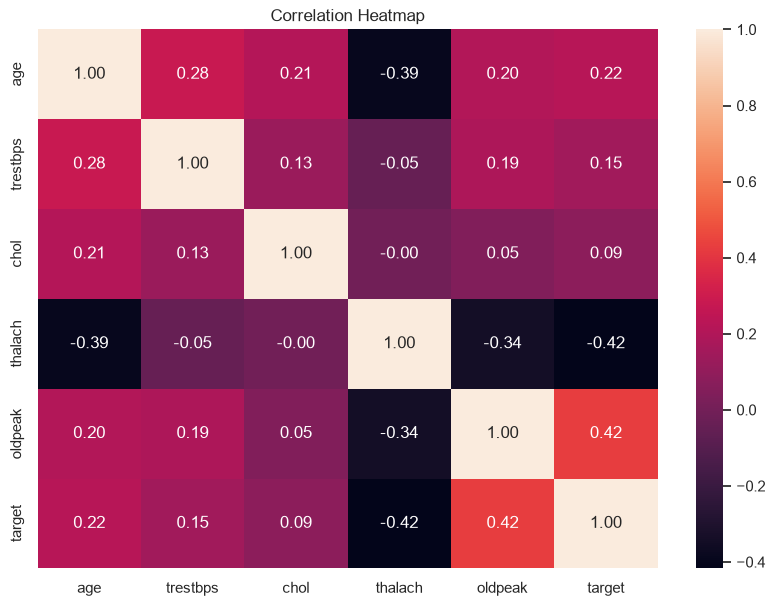

In [15]:
numeric_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak", "target"
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    df[numeric_features].corr(),
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

### OUTLIER

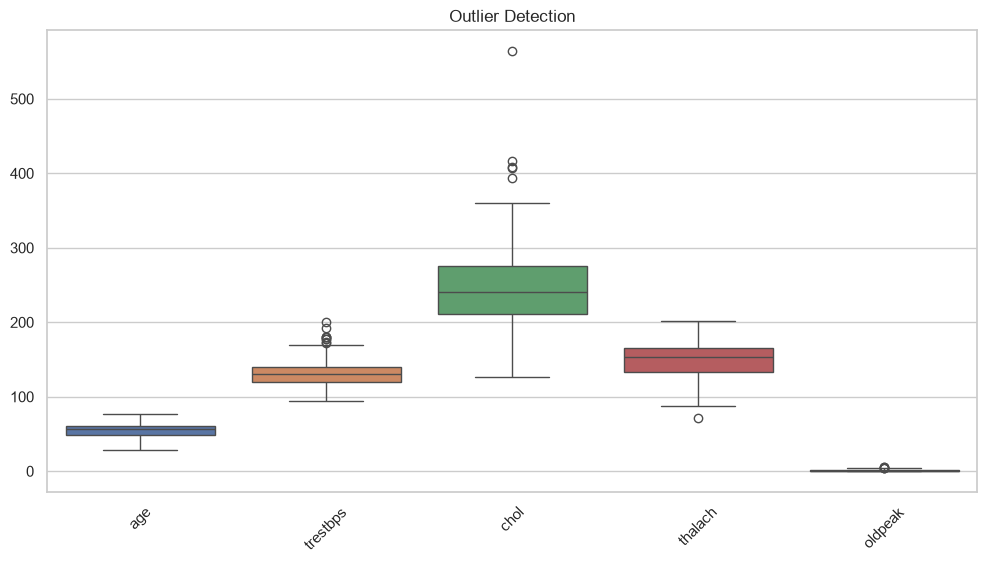

In [16]:
features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[features])

plt.title("Outlier Detection")
plt.xticks(rotation=45)
plt.show()

In [17]:
import sys
print(sys.version)
print(sys.executable)

%pip --version

3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
C:\ProgramData\anaconda3\python.exe
pip 26.1.2 from C:\ProgramData\anaconda3\Lib\site-packages\pip (python 3.14)

Note: you may need to restart the kernel to use updated packages.


In [18]:
%pip install --index-url https://pypi.org/simple fg-data-profiling==4.20.0

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [19]:
from data_profiling import ProfileReport

print("Profiling installed successfully!")

Profiling installed successfully!


In [20]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


In [21]:
df_n= df.drop(columns=['num'])
df_n.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 14/14 [00:00<00:00, 329.35it/s]


KeyboardInterrupt: 

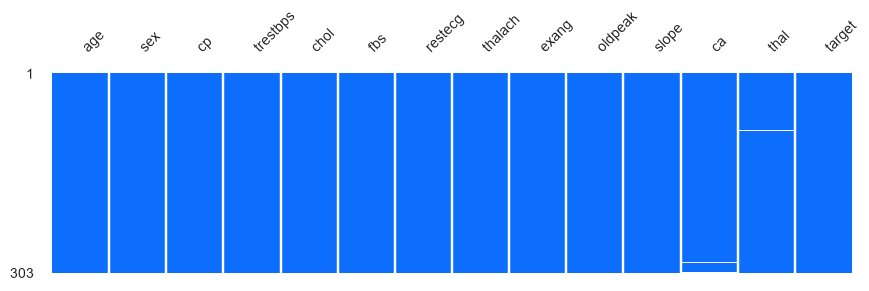

In [22]:
profile = ProfileReport(
    df_n,
    title="Heart Disease Dataset - EDA Report",
    explorative=True
)

profile.to_notebook_iframe()

In [ ]:
import os

os.makedirs("../reports", exist_ok=True)

profile.to_file(
    "../reports/uci_heart_disease_eda_report.html"
)

In [23]:
df_clean= df.copy()

missing_summary = pd.DataFrame({
    "Missing count": df_clean.isnull().sum(),
    "Missing Percentage": (df_clean.isnull().mean()*100)
})
display(missing_summary[missing_summary["Missing count"]>0])

,Missing count,Missing Percentage
ca,4,1.320132
thal,2,0.660066


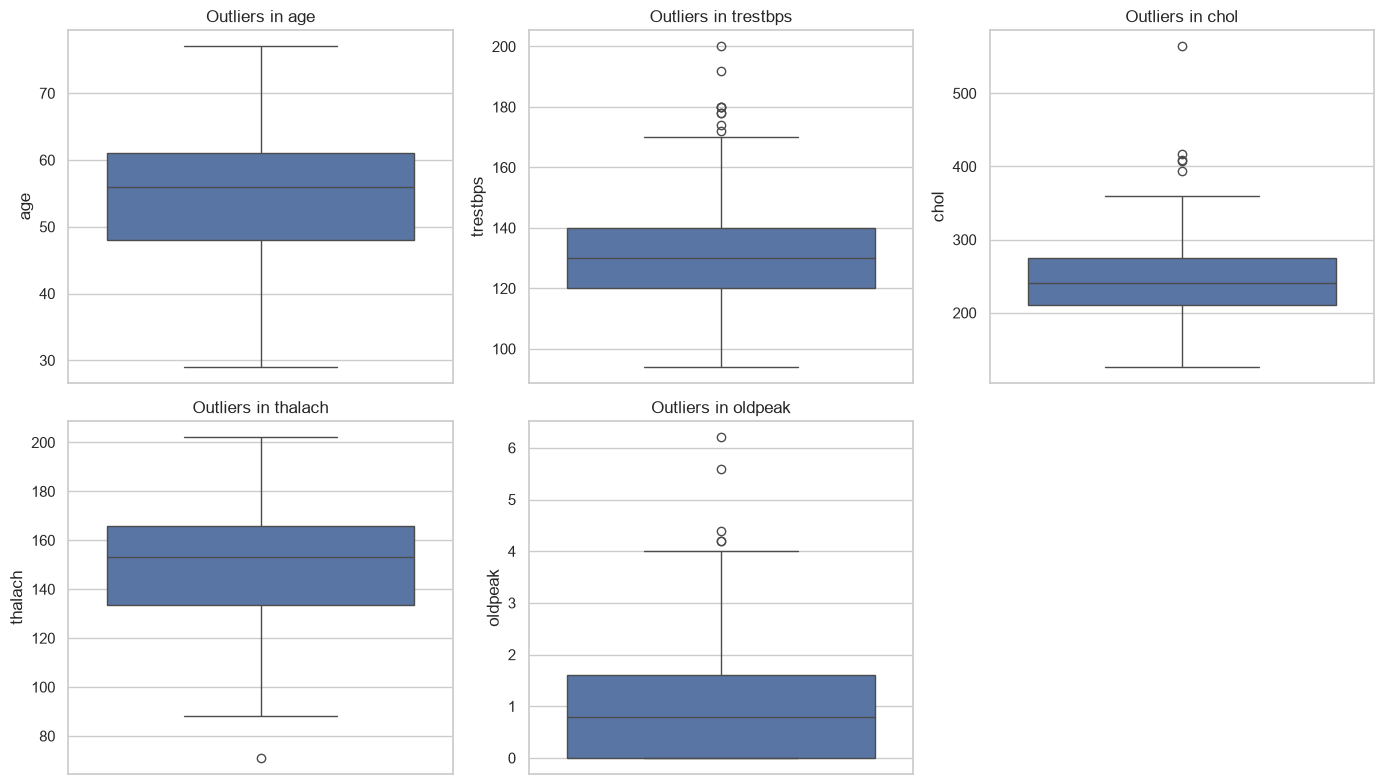

In [30]:
num_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

plt.figure(figsize=(14, 8))

for i, col in enumerate(num_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[col])
    plt.title(f"Outliers in {col}")

plt.tight_layout()
plt.show()

### IQR BOUNDARIES

In [31]:
outlier_summary = []

for col in num_features:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Outlier Count": count
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count
0,age,28.50,80.50,0
1,trestbps,90.00,170.00,9
2,chol,115.00,371.00,5
3,thalach,84.75,214.75,1
4,oldpeak,-2.40,4.00,5


In [32]:
df_clean["target"] = (
    df_clean["num"] > 0
).astype(int)

print(df_clean["target"].value_counts())

target
0    164
1    139
Name: count, dtype: int64


In [34]:
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

for col in categorical_features:
    print(df_clean[col].value_counts(dropna=False))

sex
1.0    206
0.0     97
Name: count, dtype: int64
cp
4.0    144
3.0     86
2.0     50
1.0     23
Name: count, dtype: int64
fbs
0.0    258
1.0     45
Name: count, dtype: int64
restecg
0.0    151
2.0    148
1.0      4
Name: count, dtype: int64
exang
0.0    204
1.0     99
Name: count, dtype: int64
slope
1.0    142
2.0    140
3.0     21
Name: count, dtype: int64
ca
0.0    176
1.0     65
2.0     38
3.0     20
NaN      4
Name: count, dtype: int64
thal
3.0    166
7.0    117
6.0     18
NaN      2
Name: count, dtype: int64


In [36]:
continuous_features = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

for col in continuous_features:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ][col]

    print(f"\n{col}")
    print("Outlier values:", sorted(outliers.tolist()))


age
Outlier values: []

trestbps
Outlier values: [172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180.0, 192.0, 200.0]

chol
Outlier values: [394.0, 407.0, 409.0, 417.0, 564.0]

thalach
Outlier values: [71.0]

oldpeak
Outlier values: [4.2, 4.2, 4.4, 5.6, 6.2]


In [35]:
target_column = "target"

feature_columns = [
    col for col in df_clean.columns
    if col not in ["num", "target"]
]

X = df_clean[feature_columns].copy()
y = df_clean[target_column].copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (303, 13)
Target: (303,)


In [38]:
numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal"
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [39]:
df_final = df_clean.drop(columns=["num"]).copy()

print("Final dataset shape:", df_final.shape)

display(df_final.head())

Final dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [41]:
import os
os.makedirs("../data/processed", exist_ok=True)

df_final.to_csv(
    "../data/processed/heart_disease_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [43]:
print("Final intermediate dataset:")
print("Shape:", df_final.shape)

print("\nMissing values:")
print(df_final.isnull().sum())

print("\nColumns:")
print(df_final.columns.tolist())

print("\nTarget distribution:")
print(df_final["target"].value_counts())

print("\nFirst five records:")
display(df_final.head())

Final intermediate dataset:
Shape: (303, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Target distribution:
target
0    164
1    139
Name: count, dtype: int64

First five records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [44]:
from sklearn.model_selection import train_test_split

X = df_final.drop(columns=["target"])
y = df_final["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

Training shape: (242, 13)
Testing shape: (61, 13)

Training target distribution:
target
0    131
1    111
Name: count, dtype: int64


In [45]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply same transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

Training processed shape: (242, 28)
Testing processed shape: (61, 28)


In [46]:
import pandas as pd
import numpy as np

# Check missing values after imputation
print("Training missing values:",
      np.isnan(X_train_processed).sum())

print("Testing missing values:",
      np.isnan(X_test_processed).sum())

# Check target dimensions
print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

# Check feature names
feature_names = preprocessor.get_feature_names_out()

print("\nNumber of features:", len(feature_names))
print("Feature names:")
print(feature_names.tolist())

Training missing values: 0
Testing missing values: 0

Training target: (242,)
Testing target: (61,)

Number of features: 28
Feature names:
['num__age', 'num__trestbps', 'num__chol', 'num__thalach', 'num__oldpeak', 'cat__sex_0.0', 'cat__sex_1.0', 'cat__cp_1.0', 'cat__cp_2.0', 'cat__cp_3.0', 'cat__cp_4.0', 'cat__fbs_0.0', 'cat__fbs_1.0', 'cat__restecg_0.0', 'cat__restecg_1.0', 'cat__restecg_2.0', 'cat__exang_0.0', 'cat__exang_1.0', 'cat__slope_1.0', 'cat__slope_2.0', 'cat__slope_3.0', 'cat__ca_0.0', 'cat__ca_1.0', 'cat__ca_2.0', 'cat__ca_3.0', 'cat__thal_3.0', 'cat__thal_6.0', 'cat__thal_7.0']


In [47]:
import os
import joblib
import pandas as pd

os.makedirs("../data/processed", exist_ok=True)
os.makedirs("../models", exist_ok=True)

# Convert transformed arrays into DataFrames
X_train_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_df = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

# Save datasets with targets
train_final = X_train_df.copy()
train_final["target"] = y_train.reset_index(drop=True)

test_final = X_test_df.copy()
test_final["target"] = y_test.reset_index(drop=True)

train_final.to_csv(
    "../data/processed/train_processed.csv",
    index=False
)

test_final.to_csv(
    "../data/processed/test_processed.csv",
    index=False
)

# Save fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    "../models/preprocessor.joblib"
)

print("Training dataset saved!")
print("Testing dataset saved!")
print("Preprocessor saved!")

Training dataset saved!
Testing dataset saved!
Preprocessor saved!
